In [62]:
from datascience import *
%matplotlib inline

import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np

import warnings
warnings.simplefilter("ignore")

## Percentiles ##

Definition: Let p be a number between 0 and 100. The pth percentile of a collection is the smallest value in the collection that is at least as large as p% of all the values.

In [46]:
arr = make_array(1, 2, 3, 4, 5, 6, 7, 8, 9, 10)
arr

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [47]:
# returns 2 because
#   2 is at least as large as 20% of the items in arr
#   2 is the smallest value for which this is true
percentile(20, arr)

2

In [48]:
# returns 3 because
#   3 is at least as large as 30% of the items in arr
#   3 is the smallest value for which this is true
percentile(30, arr)

3

In [49]:
# returns 3 because
#   3 is at least as large as 25% of the items in arr
#   3 is the smallest value for which this is true
percentile(25, arr)

3

## Discussion Question


In [50]:
arr2 = make_array(1, 3, 5, 7, 9)

In [51]:
# What will the following commands return?

In [52]:
# This is called the first quartile
percentile(25, arr2)

3

In [53]:
# This is called the second quartile,
# more commonly known as the median
percentile(50, arr2)

5

In [54]:
# This is called the third quartile
percentile(75, arr2)

7

## Inference: Estimation

 Below is a table of approx. 45,000 randomly sampled San Francisco employees.

In [55]:
sf = Table.read_table('san_francisco_2019.csv')
sf.show(6)

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
Public Protection,Adult Probation,Information Systems,IS Trainer-Journey,91332,0,40059,131391
Public Protection,Adult Probation,Information Systems,IS Engineer-Assistant,123241,0,49279,172520
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Senior,115715,0,46752,162468
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Principal,159394,0,57312,216706
Public Protection,Adult Probation,Information Systems,IS Programmer Analyst,70035,0,28671,98706
Public Protection,Adult Probation,Information Systems,IS Project Director,175742,0,60830,236572


### Practice

Filter out people working less than part time (use a where command) and visualize the distribution with a histogram. Compute the mean and median of the resulting data set.

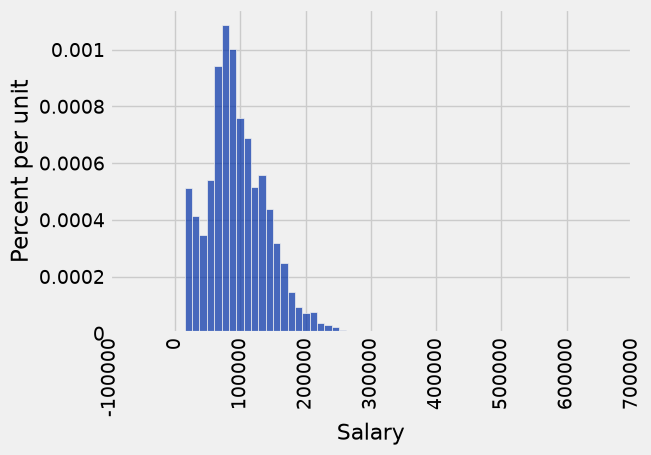

In [56]:
min_salary = 15 * 20 * 50 # $15/hr, 20 hr/wk, 50 weeks
fulltime = sf.where('Salary', are.above(min_salary))
fulltime.hist('Salary', bins = 50)

That's the median of *our sample*. What is the median of the entire population?

# Bootstrap

In the bootstrap technique, we:
 - sample randomly
 - from the original sample
 - with replacement
 - the same number of times as the original sample size

Default behavior of `tbl.sample`: at random with replacement, the same number of times as rows of `tbl`

89218.0

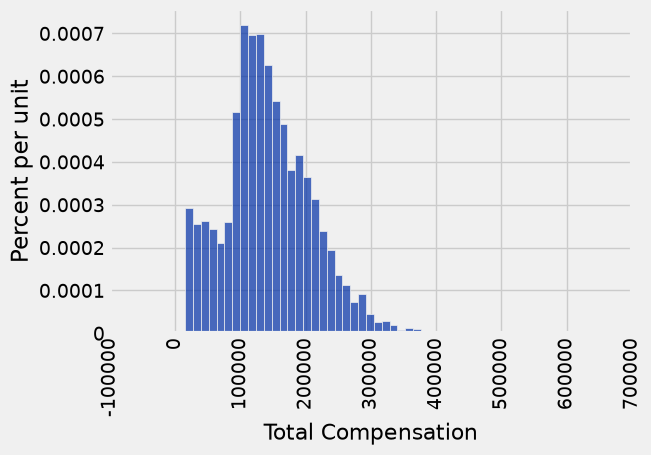

In [57]:
bootstrap_sample = sf.sample() # draw a new sample of the same size based on our data
bootstrap_sample = fulltime.sample()
bootstrap_sample.hist('Total Compensation', bins=50)
bootstrap = bootstrap_sample.column('Salary')
percentile(50, bootstrap)

### Practice

Write a function called one_bootstrap_median that resamples the table and returns the median.

In [58]:
def one_bootstrap_median():
    re_sample = fulltime.sample()
    re_sample = re_sample.column('Salary')
    perc = percentile(50, re_sample)
    return perc
one_bootstrap_median()

89221.0

In [59]:
one_bootstrap_median()

89192.0

### Practice

Simulate 1000 bootstrapped medians and gather the results into an array.

In [60]:

bootstrap_medians = make_array()

for _ in np.arange(100):
    bootstrap_medians = np.append(bootstrap_medians, bootstrap)

bootstrap_medians

array([  20054.,  130705.,   92554., ...,   67623.,   71748.,   26296.])

NameError: name 'pop_median' is not defined

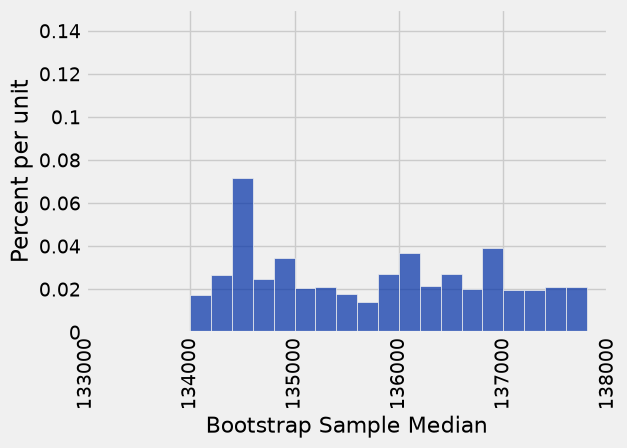

In [61]:
# Code to visualize the bootstrapped medians

resampled_medians = Table().with_column('Bootstrap Sample Median', bootstrap_medians)

median_bins=np.arange(134000, 138000, 200)
resampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
parameter_green = '#32CD32'
plots.ylim(-0.000005, 0.0015)
plots.scatter(pop_median, 0, color=parameter_green, s=40, zorder=2)
plots.title('Bootstrap Medians and the Parameter (Green Dot)');

## Percentile Method: Middle 95% of the Bootstrap Estimates 

### Practice

Find the middle 95% of the estimates by computing the 2.5 and 97.5 percentile.

In [ ]:
left = percentile(2.5) # 2.5 percentile
right = percentile() # 97.5 percentile

make_array(left, right)

In [ ]:
# Code to visualize confidence interval

resampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
plots.ylim(-0.0001, 0.0015)
plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=3, zorder=1)
plots.scatter(pop_median, 0, color=parameter_green, s=40, zorder=2);

This is called a **confidence interval**. In 95% of simulations, the median fell between these two values.

"We are 95% confident that the median salary of the entire population is between these two values."


In [ ]:
births = Table.read_table('baby.csv')
births.show(10)

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
143,299,30,66,136,True
140,351,27,68,120,False


In [ ]:
smoking = births.where('Maternal Smoker', are.equal_to(True))
smoking.show(10)

nonsmoking = births.where('Maternal Smoker', are.equal_to(False))
nonsmoking.show(10)

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
128,279,28,64,115,True
108,282,23,67,125,True
143,299,30,66,136,True
144,282,32,64,124,True
141,279,23,63,128,True
110,281,36,61,99,True
92,255,25,65,125,True
115,261,33,60,125,True
119,288,43,66,142,True
115,274,27,67,175,True


Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
140,351,27,68,120,False
114,273,30,63,154,False
115,285,38,63,130,False
144,261,33,68,170,False


In [79]:

def smoking_resample(tbl):

    resampled = tbl.sample()
    sim_weights = resampled.column('Birth Weight')
    mean = np.mean(sim_weights)

    return mean

In [83]:
smoking_resample(smoking)

113.62527233115469

In [87]:
smoking_means = make_array()
for _ in np.arange(10000):
    sim_mean = smoking_resample(smoking)
    smoking_means = np.append(smoking_means, sim_mean)

nonsmoking_means = make_array()
for _ in np.arange(10000):
    sim_mean = smoking_resample(nonsmoking)
    nonsmoking_means = np.append(nonsmoking_means, sim_mean)


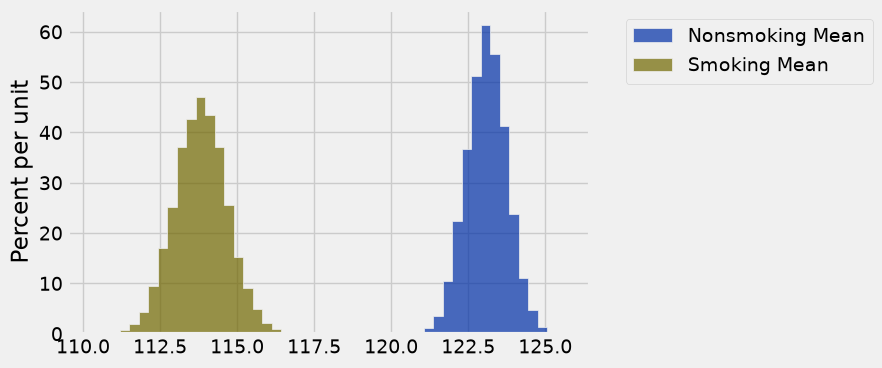

In [88]:
means_table = Table().with_columns('Nonsmoking Mean', nonsmoking_means, 'Smoking Mean', smoking_means)
means_table.hist(bins = 50)

In [90]:
smoking_left = percentile(2.5, smoking_means)
smoking_right = percentile(97.5, smoking_means)
print(smoking_left, smoking_right)

112.145969499 115.518518519


In [93]:
nonsmoking_left = percentile(2.5, nonsmoking_means)
nonsmoking_right = percentile(97.5, nonsmoking_means)
print(nonsmoking_left, nonsmoking_right)

121.812587413 124.374825175
